*Previous notebook: applying the previous techniques: a baseline network vs an improved one (L2, dropout, augmentation, early stopping, LR decay) and their comparison. — This notebook: the hyperparameter tuning process (grid search and Optuna).*

### Setup

This notebook builds on **4.1**. The cell below re-runs `4.1_baseline_vs_improved.ipynb` silently to recreate the dataset, the network helpers, `train_improved`, `regression_report` and the trained baseline / improved models. It retrains both models, so it takes a few minutes.

In [1]:
%%capture
%run "4.1_baseline_vs_improved.ipynb"

# Tuning Process

We need to tune our hyperparameters to get the best out of them. Hyperparameters are:
- Learning rate.
- Momentum beta.
- Mini-batch size.
- No. of hidden units.
- No. of layers.
- Learning rate decay.
- Regularization lambda.
- Activation functions.
- Adam beta1, beta2 & epsilon.
- ...

Its hard to decide which hyperparameter is the most important in a problem. It depends a lot on your problem. One of the ways to tune is to sample a grid with N hyperparameter settings and then try all settings combinations on your problem.

You can use Coarse to fine sampling scheme: when you find some hyperparameters values that give you a better performance - zoom into a smaller region around these values and sample more densely within this space.

---

# Using an Appropriate Scale to Pick Hyperparameters

Let's say you have a specific range for a hyperparameter from "a" to "b". It's better to search for the right ones using the logarithmic scale rather then in linear scale:

    a_log = log(a)  # e.g. a = 0.0001 then a_log = -4
    b_log = log(b)  # e.g. b = 1 then b_log = 0

    r = (a_log - b_log) * np.random.rand() + b_log
    # In the example the range would be from [-4, 0] because rand range [0,1)

    result = 10**r

It uniformly samples values in log scale from [a,b].

If we want to use the last method on exploring on the "momentum beta":

Beta best range is from 0.9 to 0.999.

You should search for 1 - beta in range 0.001 to 0.1 (1 - 0.9 and 1 - 0.999) and then use a = 0.001 and b = 0.1. Then:

    a_log = -3
    b_log = -1

    r = (a_log - b_log) * np.random.rand() + b_log

    beta = 1 - 10**r   # because 1 - beta = 10^r

---

# Hyperparameters Tuning in Practice: Pandas vs. Caviar

Intuitions about hyperparameter settings from one application area may or may not transfer to a different one.

If you don't have much computational resources you can use the "babysitting model":

- Day 0 you might initialize your parameter as random and then start training.
- Then you watch your learning curve gradually decrease over the day.
- And each day you nudge your parameters a little during training.

Called panda approach.

If you have enough computational resources, you can run some models in parallel and at the end of the day(s) you check the results.

Called Caviar approach.

In [2]:
import itertools

# ── Hyperparameter grid ───────────────────────────────────────────────────────
# Architecture and decay_rate fixed; we vary the three most sensitive knobs.
param_grid = {
    'lr0':       [1e-2, 5e-3],
    'lambd':     [1e-3, 5e-3],
    'keep_prob': [0.90, 0.95],
}

keys   = list(param_grid.keys())
combos = list(itertools.product(*param_grid.values()))
print(f'Running grid search: {len(combos)} combinations\n')

grid_results = []
for combo in combos:
    hp = dict(zip(keys, combo))
    _, _, vl, _ = train_improved(
        X_train_n, y_train, X_val_n, y_val,
        layer_sizes=[1, 64, 128, 64, 1],
        epochs=1500, patience=200, decay_rate=3e-4,
        noise_std=0.01, seed=0,
        **hp
    )
    best_val = min(vl)
    grid_results.append({**hp, 'best_val_mse': best_val})
    print(f"lr0={hp['lr0']:.4f}  λ={hp['lambd']:.4f}  keep={hp['keep_prob']:.2f}"
          f"  →  best val MSE: {best_val:.4f}")

grid_df = pd.DataFrame(grid_results).sort_values('best_val_mse').reset_index(drop=True)
print('\n── Results (ranked) ──────────────────────────────────────────')
print(grid_df.to_string(index=False))
print(f'\nBest combo: {grid_df.iloc[0].drop("best_val_mse").to_dict()}  '
      f'→  val MSE {grid_df.iloc[0]["best_val_mse"]:.4f}')

Running grid search: 8 combinations



Final train loss: 0.3564  |  val MSE: 0.3115  |  time: 65.98s
lr0=0.0100  λ=0.0010  keep=0.90  →  best val MSE: 0.3115


Final train loss: 0.2735  |  val MSE: 0.2340  |  time: 28.56s
lr0=0.0100  λ=0.0010  keep=0.95  →  best val MSE: 0.2337


Final train loss: 0.3565  |  val MSE: 0.3116  |  time: 32.83s
lr0=0.0100  λ=0.0050  keep=0.90  →  best val MSE: 0.3116


Final train loss: 0.2734  |  val MSE: 0.2340  |  time: 73.87s
lr0=0.0100  λ=0.0050  keep=0.95  →  best val MSE: 0.2337


Final train loss: 0.4364  |  val MSE: 0.3942  |  time: 95.06s
lr0=0.0050  λ=0.0010  keep=0.90  →  best val MSE: 0.3942


Final train loss: 0.3409  |  val MSE: 0.2997  |  time: 72.52s
lr0=0.0050  λ=0.0010  keep=0.95  →  best val MSE: 0.2992


Final train loss: 0.4366  |  val MSE: 0.3944  |  time: 18.60s
lr0=0.0050  λ=0.0050  keep=0.90  →  best val MSE: 0.3944


Final train loss: 0.3409  |  val MSE: 0.2997  |  time: 29.59s
lr0=0.0050  λ=0.0050  keep=0.95  →  best val MSE: 0.2992

── Results (ranked) ──────────────────────────────────────────
  lr0  lambd  keep_prob  best_val_mse
0.010  0.005       0.95      0.233687
0.010  0.001       0.95      0.233743
0.005  0.005       0.95      0.299227
0.005  0.001       0.95      0.299228
0.010  0.001       0.90      0.311503
0.010  0.005       0.90      0.311593
0.005  0.001       0.90      0.394237
0.005  0.005       0.90      0.394414

Best combo: {'lr0': 0.01, 'lambd': 0.005, 'keep_prob': 0.95}  →  val MSE 0.2337


In [3]:
!pip install optuna -q

Final train loss: 0.3691  |  val MSE: 0.3280  |  time: 66.33s
Final train loss: 0.5895  |  val MSE: 0.5641  |  time: 32.51s
Final train loss: 0.5578  |  val MSE: 0.5210  |  time: 14.43s
Final train loss: 0.2902  |  val MSE: 0.2499  |  time: 19.35s
Final train loss: 0.5084  |  val MSE: 0.4713  |  time: 34.19s
Final train loss: 0.4671  |  val MSE: 0.4224  |  time: 18.74s
Final train loss: 0.5434  |  val MSE: 0.5052  |  time: 27.27s
Final train loss: 0.2933  |  val MSE: 0.2519  |  time: 16.17s
Final train loss: 0.4483  |  val MSE: 0.4108  |  time: 12.64s
Final train loss: 0.4111  |  val MSE: 0.3711  |  time: 14.33s
Final train loss: 0.2423  |  val MSE: 0.2108  |  time: 12.63s
Final train loss: 0.3427  |  val MSE: 0.2991  |  time: 12.59s
Final train loss: 0.2561  |  val MSE: 0.2208  |  time: 12.62s
Final train loss: 0.1853  |  val MSE: 0.1563  |  time: 13.69s
Final train loss: 0.2284  |  val MSE: 0.1963  |  time: 15.00s
Final train loss: 0.2299  |  val MSE: 0.1973  |  time: 40.37s
Final tr

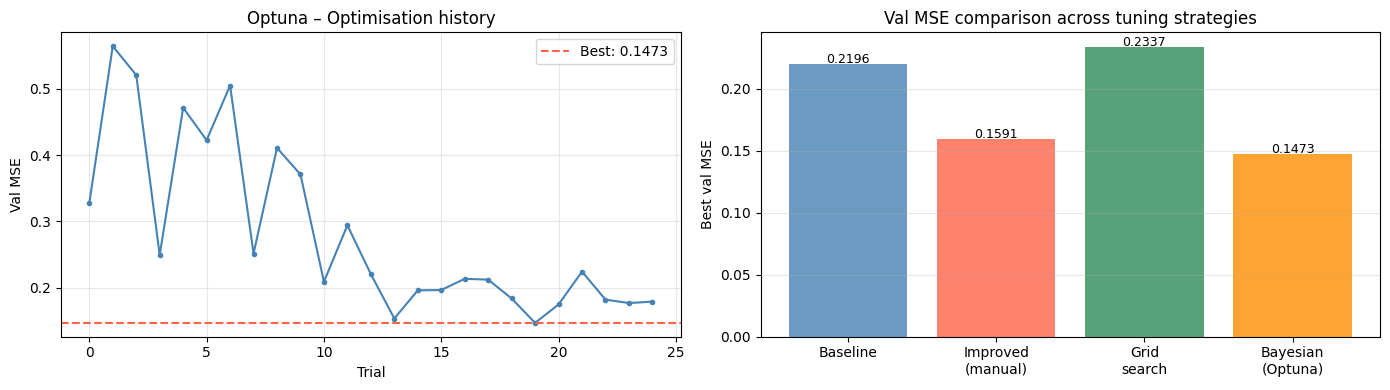

In [4]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    lr0       = trial.suggest_float('lr0',        1e-3, 5e-2, log=True)
    lambd     = trial.suggest_float('lambd',       1e-4, 1e-2, log=True)
    keep_prob = trial.suggest_float('keep_prob',   0.80, 1.00)
    decay     = trial.suggest_float('decay_rate',  1e-4, 1e-3, log=True)

    _, _, vl, _ = train_improved(
        X_train_n, y_train, X_val_n, y_val,
        layer_sizes=[1, 64, 128, 64, 1],
        epochs=1500, patience=200,
        lr0=lr0, lambd=lambd, keep_prob=keep_prob,
        decay_rate=decay, noise_std=0.01, seed=0
    )
    return min(vl)

study = optuna.create_study(direction='minimize',
                             sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=25, show_progress_bar=True)

print('\n── Optuna best result ──────────────────────────────────────')
print(f'Best val MSE : {study.best_value:.4f}')
print('Best params  :', study.best_params)

# ── Comparison bar chart ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

trials_df = study.trials_dataframe()
axes[0].plot(trials_df['value'], color='steelblue', marker='o', markersize=3)
axes[0].axhline(study.best_value, color='tomato', linestyle='--',
                label=f'Best: {study.best_value:.4f}')
axes[0].set_xlabel('Trial'); axes[0].set_ylabel('Val MSE')
axes[0].set_title('Optuna – Optimisation history')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

labels = ['Baseline', 'Improved\n(manual)', 'Grid\nsearch', 'Bayesian\n(Optuna)']
values = [min(vl_base), min(vl_imp), grid_df['best_val_mse'].min(), study.best_value]
colors = ['steelblue', 'tomato', 'seagreen', 'darkorange']
bars   = axes[1].bar(labels, values, color=colors, alpha=0.8)
axes[1].set_ylabel('Best val MSE')
axes[1].set_title('Val MSE comparison across tuning strategies')
axes[1].grid(True, alpha=0.3, axis='y')
for bar, v in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 0.001, f'{v:.4f}',
                 ha='center', fontsize=9)
plt.tight_layout()
plt.show()